# DSAI4205 · Experiment log
**Entity-level sentiment classification of tweets** | Shared baseline and five model families

[Kai B_mean artifacts on Hugging Face](https://huggingface.co/kingkaikai/DSAI4205-Qwen3-0.6B-B-mean/tree/e4b0be461caa04873b319fa4f5a44d664edf9d8b) · [Experiment records on GitHub](https://github.com/once123456/DSAI4205/tree/main/run/kai)

This notebook opens with saved results. Run All to rebuild the displays from its embedded records using pandas and IPython. No course CSV, network, GPU or training is needed. The companion **Group Implementation** notebook contains the code.

[Evaluation protocol](#protocol) · [Baseline and EDA](#shared) · [Huakai](#lb) · [Huakun](#lh) · [Jingwen](#lj) · [Yuchen](#ly) · [Phelan](#lp) · [5090 replay](#audit) · [Record index](#index)

Results come from the group repository at commit 72c90bc8daa32823f6cd5fcd48f2274de67a7e54, the November 21 pooling and B_mean archives, and the separate RTX 5090 verification of that commit. Predictions use row IDs. Full text, teacher-generated examples, feature arrays and checkpoints are excluded.

In [1]:
# Portable archive of already-saved records. Open the sections below to inspect tables.
import base64, hashlib, io, zipfile
encoded = (
    '...'
    'BgAAAADZANkAx1EAAMJNGQAAAA=='
)
archive_bytes = base64.b64decode(encoded)
assert hashlib.sha256(archive_bytes).hexdigest() == 'fb4efaebd9c3d9cfc7bc3371ac47452adf63a4e7ae6aa76f655c083663bcb1be'
ARCHIVE = zipfile.ZipFile(io.BytesIO(archive_bytes))
del encoded, archive_bytes

In [2]:
import json
import pandas as pd
from IPython.display import display, Image, Markdown
def table(path):
    return pd.read_csv(io.BytesIO(ARCHIVE.read(path)))
def report(path):
    return json.loads(ARCHIVE.read(path).decode("utf-8-sig"))
def show(path, rows=None):
    frame = table(path)
    display(frame.head(rows).round(4) if rows is not None else frame.round(4))
def figure(path):
    display(Image(data=ARCHIVE.read(path), width=690))
def paths(prefix):
    return [name for name in ARCHIVE.namelist() if name.startswith(prefix)]

<a id="protocol"></a>

## Evaluation protocol and results at a glance

The group uses four labels (0 Negative, 1 Positive, 2 Irrelevant, 3 Neutral). The common cleaned training pool has 591 rows. The 473/118 partition separates fitting and validation for methods using that split. The 397 test rows were previously inspected during the project. Treat repeated comparisons as exploratory. A 372-row sensitivity score is meaningful only for an explicitly documented overlap manifest; a subset of an inspected test set is also exposed.

Macro-F1 weights the four classes equally. Read support, precision and recall alongside it. The table identifies the training budget, evaluation population and whether the score is a seed mean. Huakun's training-only comparison is shown in its own section.

In [3]:
jpath = "runs/jingwen/results/"
bpath = "kai/b_mean/tables/"
ypath = "runs/yuchen/glove_bilstm/"
ppath = "runs/phelan/20261122_boosted_trees/"
kpath = "runs/kun/abcd_train_only_20261121/"
j = table(jpath + "comparison.csv")
b = table(bpath + "test_summary.csv").set_index("arm")
y = table(ypath + "summary.csv").query("split == 'test' and average == 'macro'").iloc[0]
p = table(ppath + "test_summary.csv").set_index("model").loc["XGBoost"]
results = []
for row in j.itertuples():
    if row.model.startswith(("L0","L4")):
        results.append([row.model,row.train_n,"archived fit",row.test_accuracy,row.test_macro_f1])
for arm in ("A_mean","B_mean"):
    results.append([arm,473,"five-seed mean",b.loc[arm,"accuracy_mean"],b.loc[arm,"macro_f1_mean"]])
results.extend([["GloVe + BiLSTM",591,"archived refit",y.accuracy,y.f1],
                ["BERT + XGBoost",473,"archived fit; test-informed adoption",p.accuracy,p.macro_f1]])
display(pd.DataFrame(results,columns=["Model (397 test rows)","Fitting rows","Summary","Accuracy","Macro-F1"]).round(4))

,Model (397 test rows),Fitting rows,Summary,Accuracy,Macro-F1
0,L0 TF-IDF + LR (shared baseline),473,archived fit,0.4912,0.4461
1,L4 six views (prompt ensemble) + multi-kernel SVM,473,archived fit,0.6071,0.5793
2,L4 refit on all 591 rows,591,archived fit,0.6222,0.5974
3,"L0 TF-IDF + LR, 591 rows",591,archived fit,0.5063,0.4662
4,A_mean,473,five-seed mean,0.5078,0.4838
5,B_mean,473,five-seed mean,0.5154,0.4961
6,GloVe + BiLSTM,591,archived refit,0.4610,0.4371
7,BERT + XGBoost,473,archived fit; test-informed adoption,0.5441,0.5217


<a id="shared"></a>

## Shared baseline and exploratory analysis

The word TF-IDF and logistic regression reference reaches macro-F1 0.4461 with 473 fitting rows and 0.4662 after the 591-row fit. Match the fitting budget before quoting a gain. Inspect class frequency and the confusion matrix to interpret minority-class scores. The archive also contains length, surface-feature, entity-mention and feature-correlation plots.

,sentiment,n,median_words,mean_words,mean_exclaim,mean_question,share_exclaim,share_question,share_url,share_mention,mean_caps_ratio,share_negation,share_game_word,share_brand_word,mean_content_types
0,Negative,174,19.0,22.94,0.356,0.351,0.109,0.259,0.086,0.391,0.120,0.374,0.414,0.138,10.98
1,Positive,165,14.0,19.10,0.473,0.097,0.212,0.091,0.127,0.255,0.111,0.182,0.400,0.103,9.19
2,Irrelevant,106,18.0,22.31,0.406,0.340,0.198,0.170,0.283,0.283,0.123,0.198,0.453,0.066,10.30
3,Neutral,146,17.0,20.84,0.466,0.315,0.260,0.205,0.384,0.178,0.100,0.192,0.274,0.288,10.40


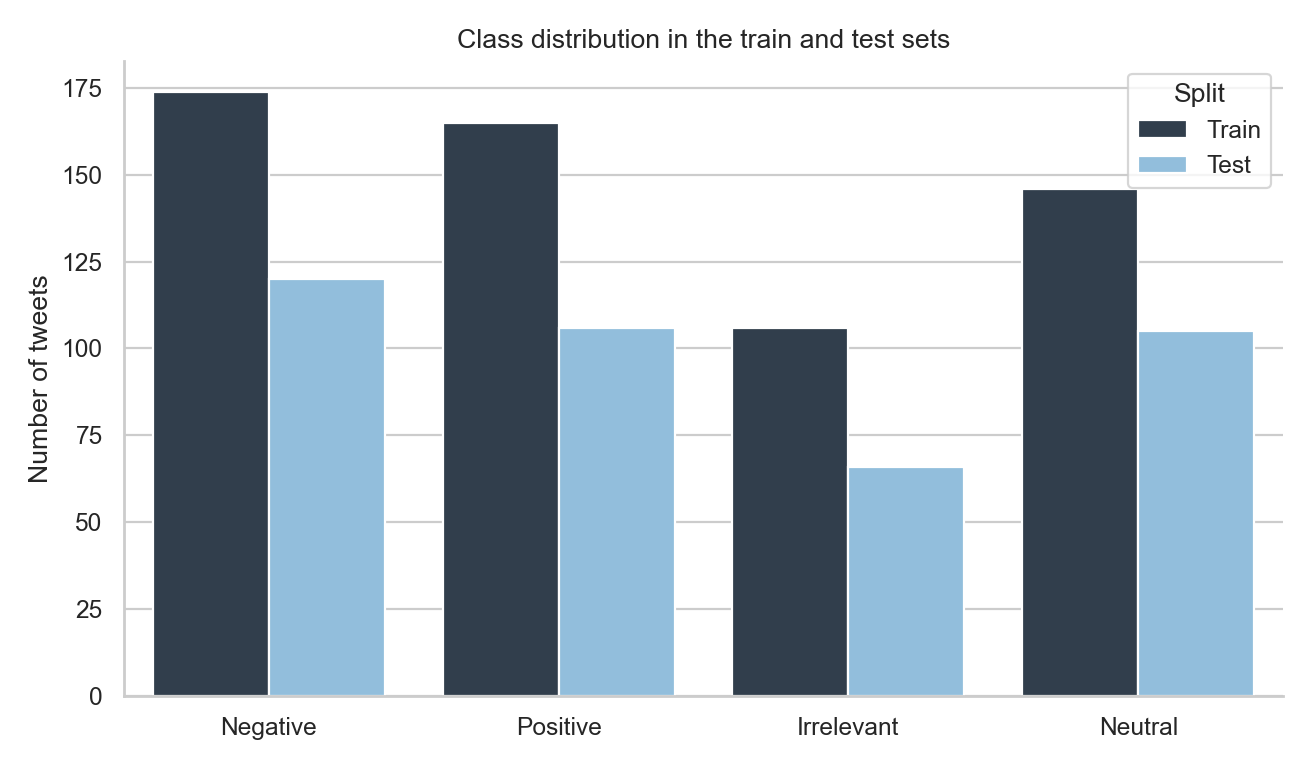

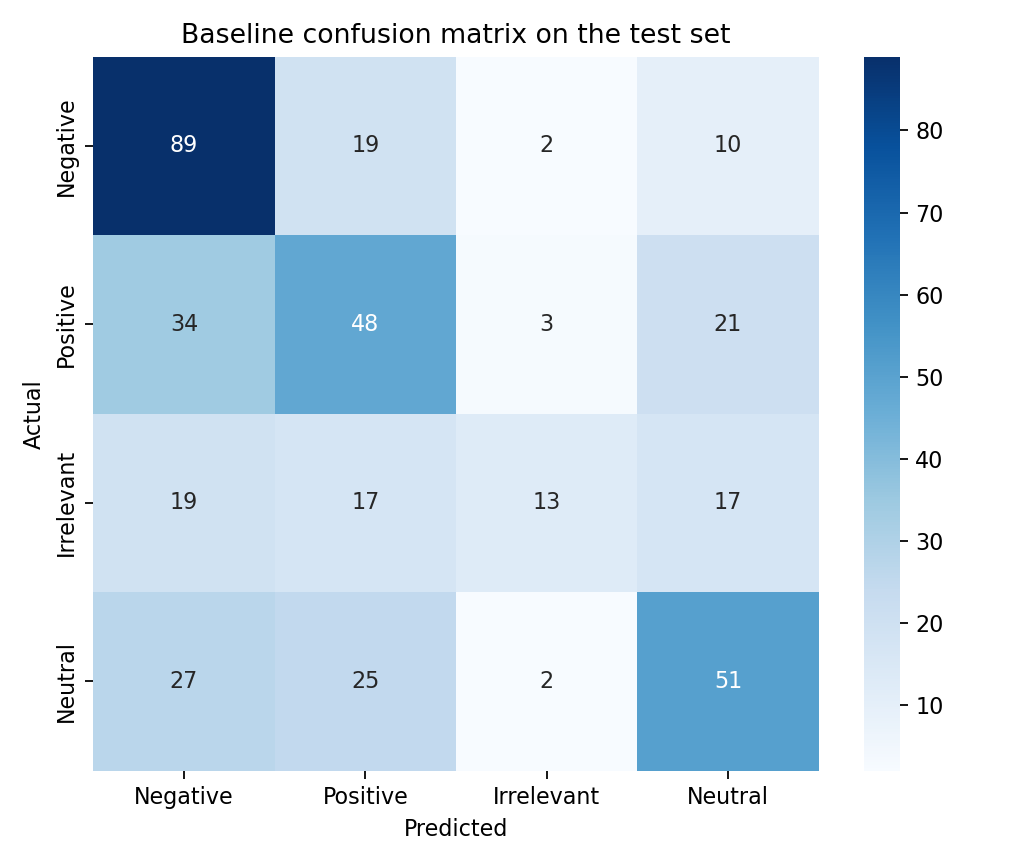

In [4]:
show("reports/class_profile.csv")
figure("figures/01_class_distribution.png")
figure("figures/13_baseline_confusion.png")

<a id="lb"></a>

## Huakai Huang · Qwen pooling and classification-loss LoRA

The pooling ablation keeps the MLP and five seeds fixed while changing which final-layer states represent a tweet. B_mean then adapts Qwen3-0.6B with a temporary four-class head, freezes the selected LoRA encoder, and fits a fresh MLP on normalized comment-token means. Compare B_mean with A_mean on the same seeds and row IDs.

B_mean gains 0.0123 macro-F1 on average. The paired bootstrap interval includes zero (−0.0215 to +0.0475). Positive gains about 0.045 class F1 and Irrelevant gains 0.021, while Negative drops 0.004 and Neutral drops 0.013. The result supports a modest observed improvement; it does not establish reliable improvement across future samples. The seed-42 matrix below is one run. The aggregate tables average five.

In [5]:
show("kai/pooling/tables/test_summary.csv")
show(bpath + "main_results_readable.csv")
show(bpath + "class_comparison_readable.csv")
show(bpath + "paired_bootstrap.csv")
show(bpath + "confusion_B_mean_seed42.csv")
show(bpath + "efficiency.csv")

,pooling,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,ece10_mean,ece10_std,ece15_mean,ece15_std,nll_mean,nll_std,brier_mean,brier_std
0,comment_last,0.4484,0.0204,0.4221,0.0253,0.4441,0.0232,0.2338,0.0614,0.2356,0.0619,1.6038,0.2082,0.7580,0.0314
1,comment_mean,0.5078,0.0162,0.4838,0.0218,0.5021,0.0189,0.1861,0.0267,0.1851,0.0274,1.3608,0.0664,0.6748,0.0143
2,template_last,0.5063,0.0185,0.4625,0.0113,0.4939,0.0136,0.1891,0.0516,0.1894,0.0523,1.4329,0.1375,0.6870,0.0299


,模型,Macro-F1,Weighted-F1,Accuracy,ECE10
0,A_mean,0.4838 ± 0.0218,0.5021 ± 0.0189,0.5078 ± 0.0162,0.1861 ± 0.0267
1,B_mean,0.4961 ± 0.0147,0.5130 ± 0.0160,0.5154 ± 0.0164,0.2303 ± 0.0237
2,B_temporary_head,0.4818 ± 0.0283,0.5033 ± 0.0196,0.5139 ± 0.0130,0.1673 ± 0.0985


,ID,类别,A_mean precision,A_mean recall,A_mean f1,B_mean precision,B_mean recall,B_mean f1,F1差值
0,0,Negative,0.5564,0.6183,0.5856,0.5682,0.5967,0.5819,-0.0037
1,1,Positive,0.4834,0.4642,0.4728,0.5341,0.5038,0.5178,0.0449
2,2,Irrelevant,0.3913,0.2970,0.3364,0.3812,0.3364,0.3572,0.0208
3,3,Neutral,0.5271,0.5581,0.5403,0.5105,0.5467,0.5276,-0.0127


,treatment,control,mean_delta_macro_f1,ci_low,ci_high,resamples
0,B_mean,A_mean,0.0123,-0.0215,0.0475,2000
1,B_temporary_head,B_mean,-0.0143,-0.0472,0.0158,2000


,Unnamed: 0,Negative,Positive,Irrelevant,Neutral
0,Negative,71,22,12,15
1,Positive,16,58,11,21
2,Irrelevant,15,12,20,19
3,Neutral,20,19,10,56


,arm,batch_size,seed,samples_timed,repeats,p50_request_ms,p95_request_ms,seconds_per_1000,samples_per_second,peak_allocated_MiB,peak_reserved_MiB,usd_per_1000_warm_compute,cached_model_load_seconds,seed42_predictions_reproduced
0,A_mean,1,42,64,1,20.6432,21.0828,20.9446,47.7449,1183.5757,1308.0,0.0029,0.5028,True
1,A_mean,8,42,1191,3,26.4103,27.4961,3.3558,297.9943,1240.2344,1308.0,0.0005,0.5028,True
2,B_mean,1,42,64,1,34.9048,35.1957,34.9026,28.6512,1192.2163,1322.0,0.0049,0.4751,True
3,B_mean,8,42,1191,3,40.8544,41.2511,5.1407,194.5269,1262.9165,1322.0,0.0007,0.4751,True


Earlier experiments compared label-only generation, explanation distillation and counterfactual augmentation. The original summaries below use their own objectives and run configurations. Per-epoch B_mean logs and ID-level test predictions for the pooling and B_mean experiments can be opened through the record index.

In [6]:
for name in ("label_only", "rationale_distillation", "counterfactual"):
    note = ARCHIVE.read("runs/kai/" + name + "_summary.md").decode("utf-8-sig")
    display(Markdown(note))

# label-only 结果汇总

- Run: `qwen_lora_runs/20261114T085807_400102Z_seed42`
- 模型: Qwen3-0.6B + LoRA；验证选 checkpoint-180
- 验证 macro-F1: **0.5374**；训练约 611s；峰值显存 2.62 GiB

## 测试集（397）

| 指标 | 本实验 | TF-IDF+LR 基线 | 差值 |
|---|---:|---:|---:|
| macro-F1 | **0.4850** | 0.4461 | +0.0389 |
| accuracy | **0.5088** | 0.4912 | +0.0176 |

### 各类别 F1

| 类别 | precision | recall | f1 |
|---|---:|---:|---:|
| Negative | 0.618 | 0.633 | 0.626 |
| Positive | 0.529 | 0.604 | 0.564 |
| Irrelevant | 0.253 | 0.318 | 0.282 |
| Neutral | 0.586 | 0.390 | 0.469 |

## 结论

原始标签 LoRA 在同划分测试上超过共享基线（macro-F1 +3.9 个百分点）。Irrelevant 仍最弱；Neutral 召回偏低。


# rationale-distillation 结果汇总

- Run: `qwen_distillation_runs/20261114T090915_982382Z_seed42`
- 教师: DeepSeek `deepseek-v4-pro`（thinking disabled），946 次请求，约 326k tokens
- ZIP: `qwen3_rationale_distillation.zip`

## 教师筛选覆盖率

| Sentiment | total | format_valid | accepted | acceptance_rate |
|---|---:|---:|---:|---:|
| Negative | 140 | 136 | 84 | 60.0% |
| Positive | 132 | 130 | 78 | 59.1% |
| Irrelevant | 85 | 83 | 6 | 7.1% |
| Neutral | 116 | 115 | 25 | 21.6% |

辅助解释行数：unfiltered **464** / filtered **193**（共 473 训练行）。

## 测试对照（seed=42，相对 label_only）

| 实验 | test macro-F1 | test accuracy | delta_macro_f1 | 95% bootstrap CI |
|---|---:|---:|---:|---|
| label_only | 0.4745 | 0.4912 | 0 | — |
| rationale_unfiltered | **0.4886** | 0.5063 | **+0.0141** | [-0.0195, 0.0508] |
| rationale_filtered | 0.4759 | 0.5063 | +0.0014 | [-0.0381, 0.0442] |

## 结论

- 加入格式有效短解释（unfiltered）相对同对照 label_only 有约 **+1.4** 个百分点 macro-F1，但 bootstrap 区间跨 0，单种子下尚不能断言显著。
- 严格筛选后 accepted 仅约 41% 训练行（尤其 Irrelevant/Neutral 很低），filtered 几乎回到 label_only（+0.14 pp），说明**筛得过严、覆盖不足**，本设置下筛选未带来额外增益。
- 与独立第一阶段 label-only（test macro-F1 0.485）相比，蒸馏内 label_only 为 0.475：同协议对照以本表为准；跨 run 波动约 1 pp。


# counterfactual 结果汇总

- Run: `qwen_counterfactual_runs/20261114T102655_279072Z_seed42`
- 导入蒸馏 ZIP：`qwen3_rationale_distillation.zip`（deepseek-v4-pro）
- 反事实 API：142 次新请求；父样本 80，通过核验 **46**
- ZIP：`qwen3_counterfactual.zip`

## 反事实接受情况

| source_label | attempted | accepted | rate |
|---|---:|---:|---:|
| Negative (0) | 40 | 14 | 35% |
| Positive (1) | 40 | 32 | 80% |

主要拒绝原因：`wrong_polarity` 15、`nonlocal_or_protected_edit` 13。

## 测试对照（相对 rationale_filtered）

| 实验 | test macro-F1 | test accuracy | delta_macro_f1 | 95% CI |
|---|---:|---:|---:|---|
| rationale_filtered | 0.4855 | 0.5365 | 0 | — |
| rationale_filtered_cf | 0.4873 | 0.4987 | **+0.0017** | [-0.0408, 0.0471] |

## 结论

加入 46 条通过核验的情感翻转样本后，macro-F1 仅 **+0.17 pp**，bootstrap 区间跨 0。负向父样本接受率偏低，增强信号有限；本设置下反事实增强未显示可靠增益。


<a id="lh"></a>

## Huakun Huang · ELMo and TextCNN A–D ablation

These are training-only grouped cross-validation results. Compare pooled out-of-fold macro-F1 with the same column across variants. Its value can differ from the arithmetic mean of fold F1 scores. D reaches 0.4035 against A at 0.4006. The difference is small relative to the recorded fold variability. The archive contains author-supplied aggregate, seed and fold tables. A comparable 397-row test score is unavailable.

,variant,accuracy,macro_precision,macro_recall,pooled_macro_f1,fold_mean_f1,fold_sd_f1,Irrelevant_precision,Irrelevant_recall,Negative_precision,Negative_recall,delta_vs_A
0,A,0.4179,0.4016,0.4006,0.4006,0.3958,0.0197,0.2232,0.2358,0.4919,0.5230,0.0000
1,B,0.4146,0.3878,0.3921,0.3892,0.3830,0.0189,0.2093,0.1698,0.4815,0.5230,-0.0114
2,C,0.4399,0.3959,0.4057,0.3872,0.3831,0.0341,0.2258,0.0660,0.4581,0.5977,-0.0133
3,D,0.4162,0.4184,0.4011,0.4035,0.3966,0.0242,0.2206,0.2830,0.4700,0.5402,0.0030


,variant,seed,pooled_macro_f1,accuracy
0,A,101,0.3955,0.4061
1,A,102,0.3999,0.4230
2,A,103,0.3932,0.4095
3,A,104,0.3927,0.4146
4,A,105,0.4109,0.4264
5,B,101,0.3807,0.4010
6,B,102,0.4025,0.4247
7,B,103,0.4021,0.4264
8,B,104,0.3700,0.3959
9,B,105,0.3967,0.4196


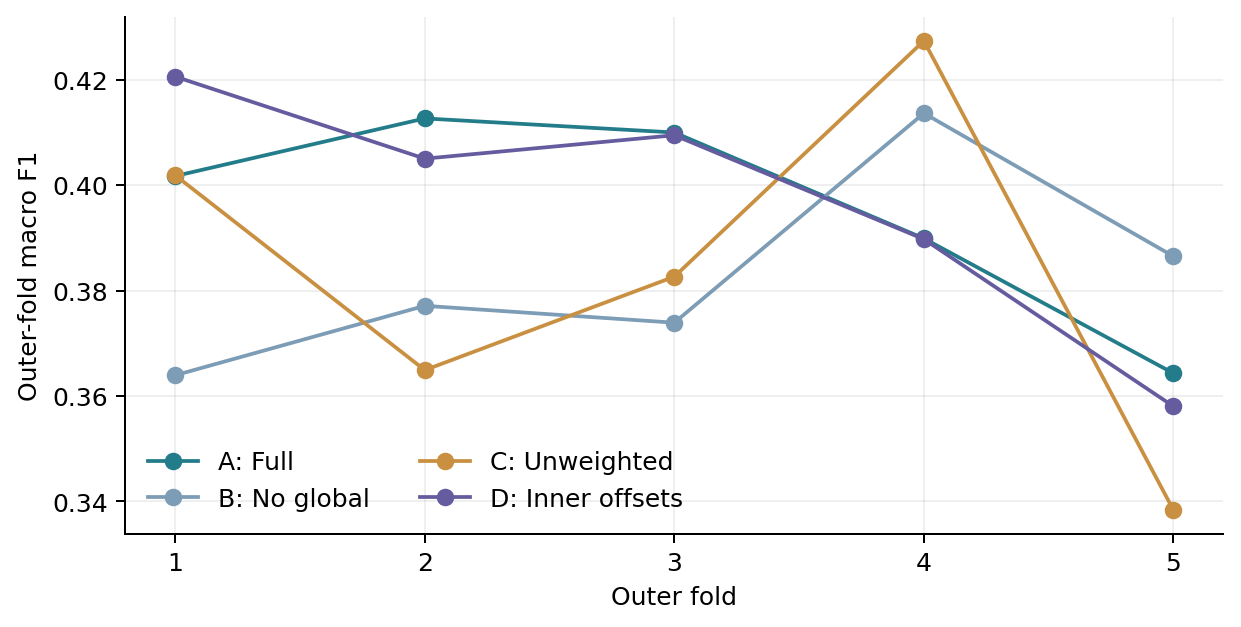

In [7]:
show(kpath + "summary_metrics.csv")
show(kpath + "seed_summary.csv")
figure(kpath + "figures/fold_comparison.png")

<a id="lj"></a>

## Jingwen Yang · multi-view SVM

The ladder changes from TF-IDF to frozen encoders, then combines instruction-conditioned views with a multi-kernel SVM. With 473 fitting rows, L3 scores 0.5903 macro-F1 and L4 scores 0.5793. Expanding from three views to six did not improve this test result. The six-view model refitted on 591 rows scores 0.5974. Its matched full-pool TF-IDF reference scores 0.4662. Per-class scores and paired comparisons are preserved alongside the chosen settings and validation records.

In [8]:
display(j.round(4))
show(jpath + "paired_bootstrap.csv")
show(jpath + "per_class_metrics.csv", 8)

,model,train_n,val_macro_f1,test_accuracy,test_macro_f1,test_macro_f1_without_paraphrases,Negative_f1,Positive_f1,Irrelevant_f1,Neutral_f1
0,L0 TF-IDF + LR (shared baseline),473,0.3909,0.4912,0.4461,0.4165,0.5887,0.4279,0.2564,0.5114
1,L1 bge-large + SVM,473,0.4919,0.5743,0.5382,0.5063,0.6963,0.5797,0.3455,0.5314
2,L2 e5-instruct sentiment view + SVM,473,0.5499,0.5592,0.5242,0.4993,0.6970,0.5648,0.2946,0.5405
3,L3 three task views + multi-kernel SVM,473,0.4652,0.6096,0.5903,0.5733,0.7063,0.6346,0.4276,0.5926
4,L4 six views (prompt ensemble) + multi-kernel SVM,473,0.4961,0.6071,0.5793,0.5629,0.6970,0.6436,0.3582,0.6186
5,L4 refit on all 591 rows,591,NaN,0.6222,0.5974,0.5805,0.7023,0.6540,0.4186,0.6146
6,"L0 TF-IDF + LR, 591 rows",591,NaN,0.5063,0.4662,0.4286,0.6159,0.4465,0.3023,0.5000


,treatment,control,delta_macro_f1,delta_ci_low,delta_ci_high,resamples
0,L1 bge-large + SVM,L0 TF-IDF + LR (shared baseline),0.0921,0.0385,0.1454,1000
1,L2 e5-instruct sentiment view + SVM,L0 TF-IDF + LR (shared baseline),0.0781,0.0240,0.1321,1000
2,L3 three task views + multi-kernel SVM,L0 TF-IDF + LR (shared baseline),0.1442,0.0846,0.1982,1000
3,L4 six views (prompt ensemble) + multi-kernel SVM,L0 TF-IDF + LR (shared baseline),0.1332,0.0789,0.1864,1000
4,L4 refit on all 591 rows,"L0 TF-IDF + LR, 591 rows",0.1312,0.0743,0.1866,1000
5,L4 six views (prompt ensemble) + multi-kernel SVM,L1 bge-large + SVM,0.0411,-0.0032,0.0848,1000


,model,label,precision,recall,f1,support
0,L0 TF-IDF + LR (shared baseline),Negative,0.5123,0.6917,0.5887,120
1,L0 TF-IDF + LR (shared baseline),Positive,0.4220,0.4340,0.4279,106
2,L0 TF-IDF + LR (shared baseline),Irrelevant,0.8333,0.1515,0.2564,66
3,L0 TF-IDF + LR (shared baseline),Neutral,0.4912,0.5333,0.5114,105
4,L1 bge-large + SVM,Negative,0.6267,0.7833,0.6963,120
5,L1 bge-large + SVM,Positive,0.5941,0.5660,0.5797,106
6,L1 bge-large + SVM,Irrelevant,0.4318,0.2879,0.3455,66
7,L1 bge-large + SVM,Neutral,0.5392,0.5238,0.5314,105


<a id="ly"></a>

## Yuchen Gu · GloVe-Twitter and BiLSTM

The selected configuration scores 0.4962 validation macro-F1. After refitting, its recorded test macro-F1 is 0.4371, below the 591-row TF-IDF result. The validation and test scores describe different samples. The archive retains the search table, epoch history, confusion matrix, per-class support and ID-only error examples.

In [9]:
show(ypath + "summary.csv")
show(ypath + "per_class.csv")
show(ypath + "validation_search.csv", 8)
show(ypath + "confusion_matrix.csv")

,split,average,accuracy,precision,recall,f1,n
0,validation,macro,0.5169,0.5056,0.5151,0.4962,118
1,validation,weighted,0.5169,0.5110,0.5169,0.5007,118
2,test,macro,0.4610,0.4505,0.4378,0.4371,397
3,test,weighted,0.4610,0.4751,0.4610,0.4606,397


,split,label,precision,recall,f1-score,support
0,validation,Negative,0.5667,0.4722,0.5152,36
1,validation,Positive,0.5122,0.6774,0.5833,31
2,validation,Irrelevant,0.4286,0.2308,0.3000,26
3,validation,Neutral,0.5152,0.6800,0.5862,25
4,test,Negative,0.5161,0.5333,0.5246,120
5,test,Positive,0.4662,0.5849,0.5188,106
6,test,Irrelevant,0.2254,0.2424,0.2336,66
7,test,Neutral,0.5942,0.3905,0.4713,105


,model,hidden,dropout,finetune,best_epoch,validation_macro_f1
0,BiLSTM,16,0.4,False,12,0.4134
1,BiLSTM,16,0.4,True,12,0.4037
2,BiLSTM,48,0.4,False,12,0.4685
3,BiLSTM,48,0.4,True,12,0.4529


,split,actual,Negative,Positive,Irrelevant,Neutral
0,validation,Negative,17,10,5,4
1,validation,Positive,2,21,3,5
2,validation,Irrelevant,8,5,6,7
3,validation,Neutral,3,5,0,17
4,test,Negative,64,26,22,8
5,test,Positive,19,62,16,9
6,test,Irrelevant,19,20,16,11
7,test,Neutral,22,25,17,41


<a id="lp"></a>

## Phelan · BERT and classifier refinement

The original BERT + MLP, later MLP refinements, transfer experiments and boosted-tree comparison are recorded separately. In the archived test comparison XGBoost scores 0.5217 macro-F1 against 0.4971 for MLP v4. The selection decision used the inspected test set, so its advantage is exploratory. The later 5090 run returned 0.5048 for XGBoost; retain both values and their provenance.

,model,accuracy,macro_precision,macro_recall,macro_f1
0,MLP_v4,0.5113,0.5059,0.4975,0.4971
1,XGBoost,0.5441,0.5313,0.5195,0.5217
2,LightGBM,0.5315,0.5142,0.5066,0.5076


,model,label,precision,recall,f1-score,support
0,MLP_v4,Negative,0.5917,0.5917,0.5917,120.0
1,MLP_v4,Positive,0.5179,0.5472,0.5321,106.0
2,MLP_v4,Irrelevant,0.2989,0.3939,0.3399,66.0
3,MLP_v4,Neutral,0.6154,0.4571,0.5246,105.0
4,XGBoost,Negative,0.5385,0.6417,0.5856,120.0
5,XGBoost,Positive,0.5351,0.5755,0.5545,106.0
6,XGBoost,Irrelevant,0.3889,0.3182,0.3500,66.0
7,XGBoost,Neutral,0.6628,0.5429,0.5969,105.0
8,LightGBM,Negative,0.5315,0.6333,0.5779,120.0
9,LightGBM,Positive,0.5556,0.5660,0.5607,106.0


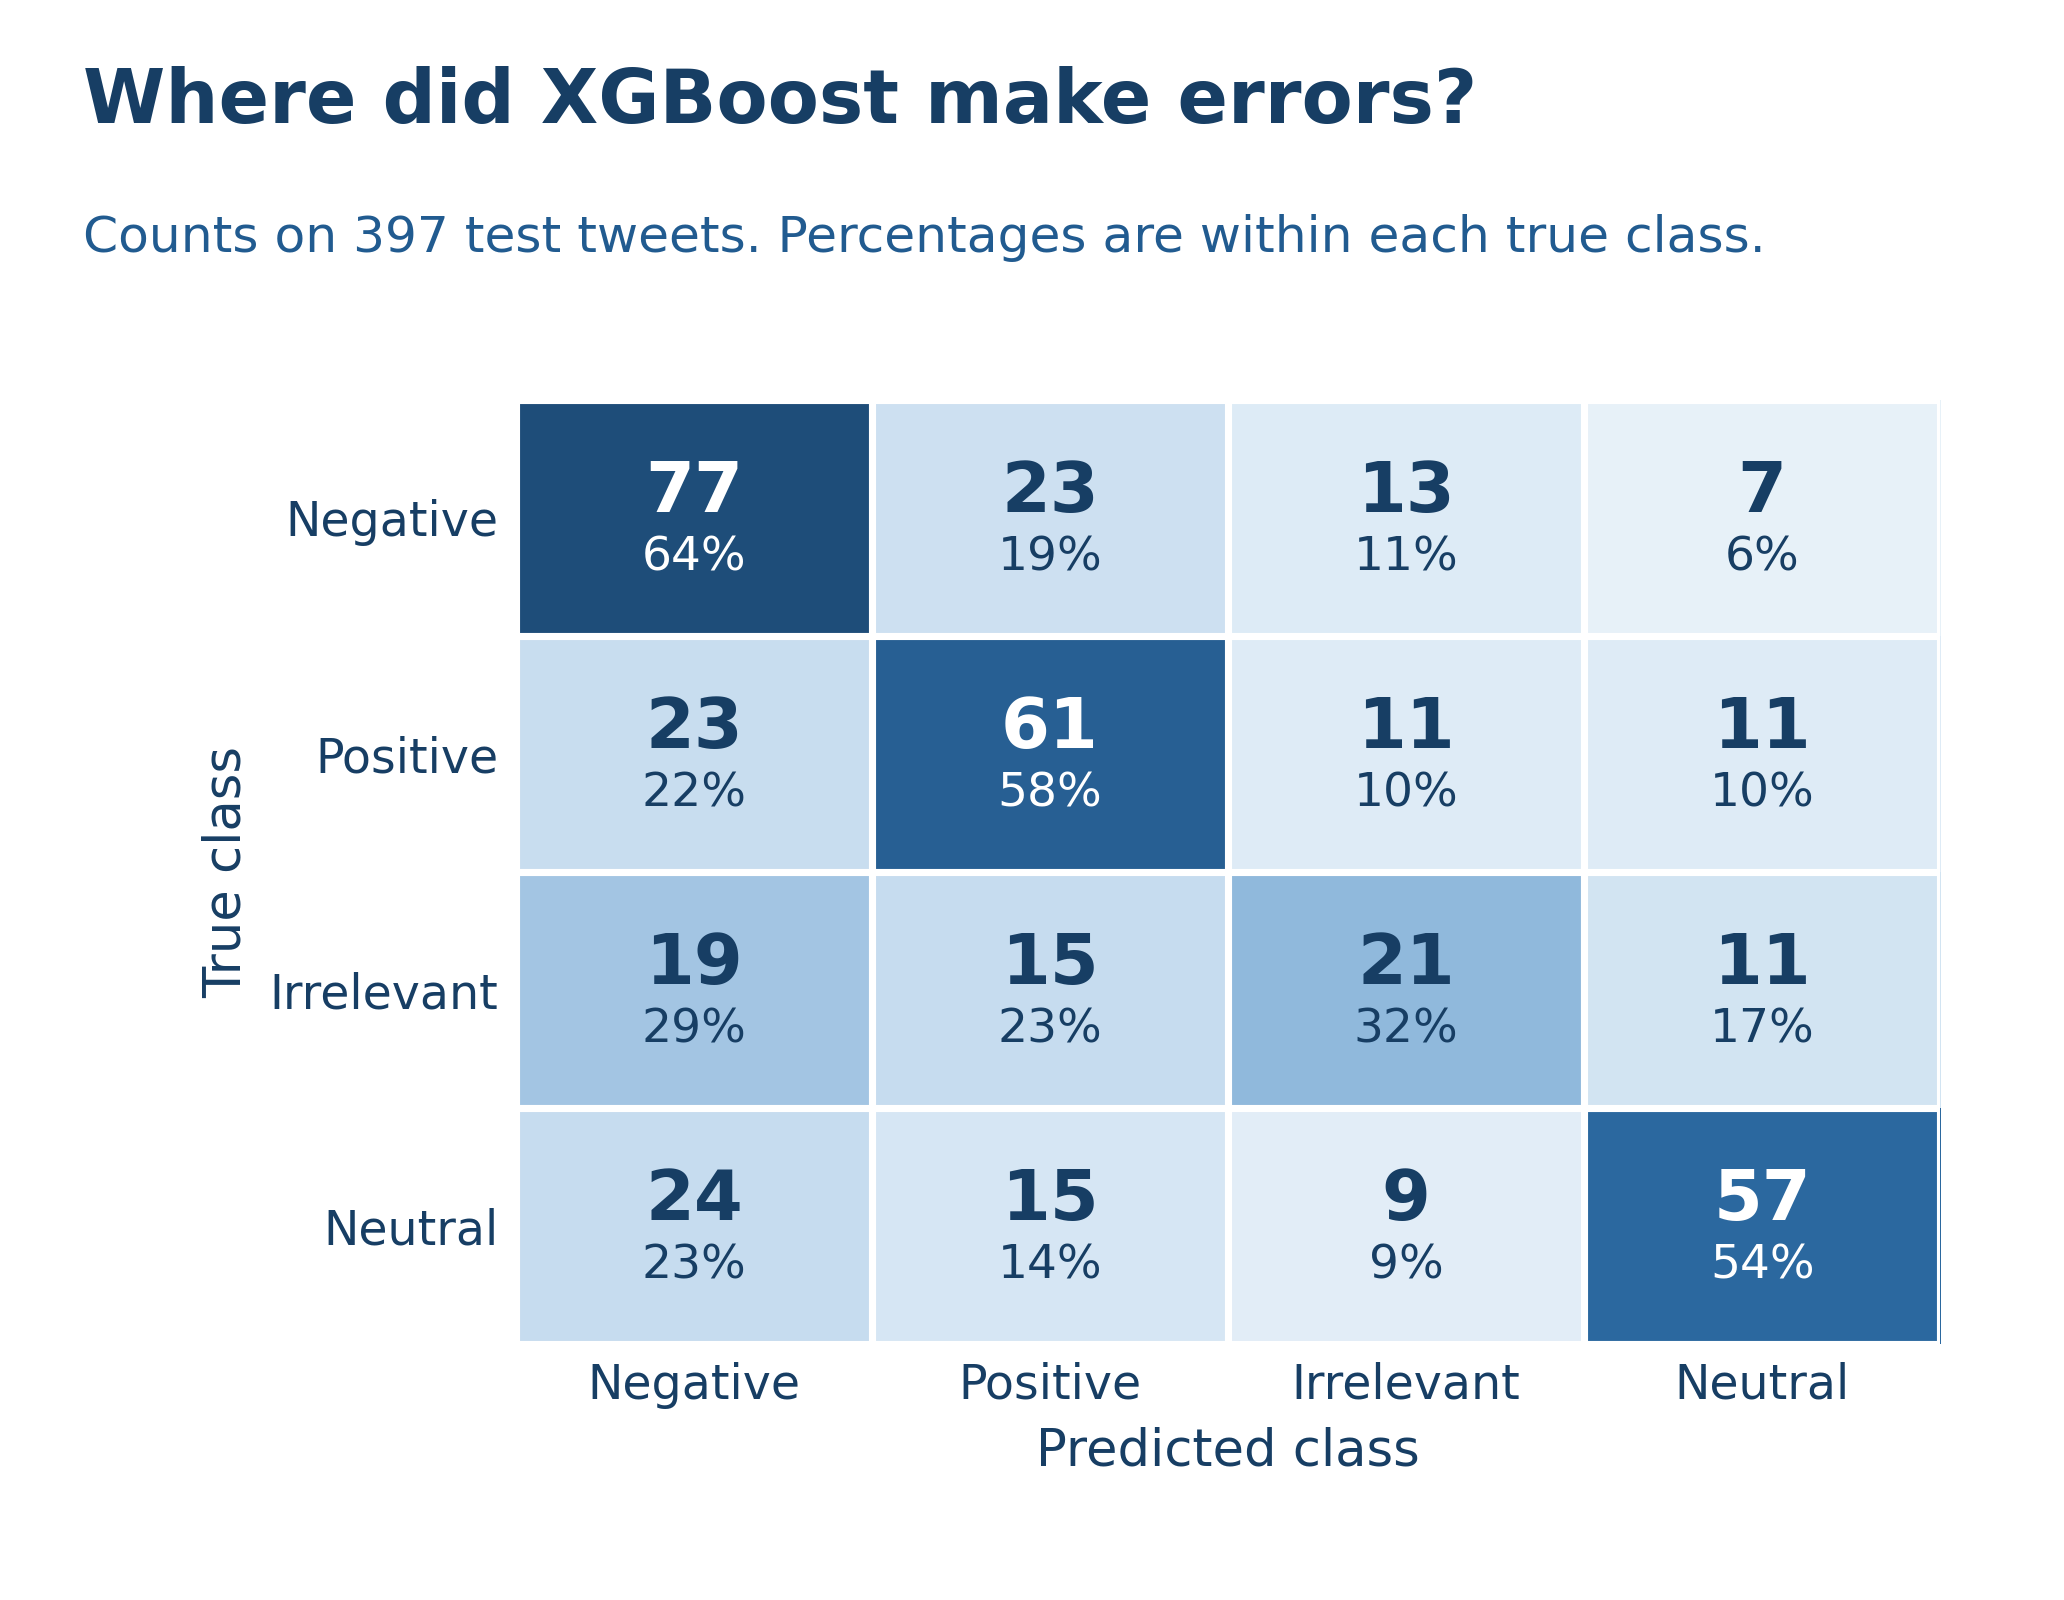

In [10]:
show(ppath + "test_summary.csv")
show(ppath + "test_by_class.csv")
figure(ppath + "fig/confusion_matrix_xgboost.png")

<a id="audit"></a>

## RTX 5090 verification of the source revision

This is the previous remote validation, recorded separately from the student experiments. Kun's report loaded, while its training entry point required the unavailable elmo_vendor module. The first GloVe preparation attempt reported a missing wrapt package; the later Yuchen run completed. Kai's generative label-only path failed the adapter reload consistency assertion in both smoke and default runs. The archived seed-42 A_mean and B_mean prediction replay matched all 397 labels and row IDs. Replay uses saved artifacts. These checks do not constitute a new five-seed training run.

In [11]:
audit = report("validation/rtx5090.json")
print(audit["gpu"], audit["commit"])
display(pd.DataFrame(audit["checks"]))
for evidence in audit["stored_replay"]:
    print(evidence)
print("Observed adapter reload diagnostics:", audit["adapter_reload"])

NVIDIA GeForce RTX 5090, 32607 MiB, 580.178.04 72c90bc8daa32823f6cd5fcd48f2274de67a7e54


,name,status,rc,seconds
0,glove-prep,failed,1,0.16
1,baseline,pass,0,0.97
2,kun-report,pass,0,0.36
3,kun-train,failed,1,1.57
4,kai-split,pass,0,0.71
5,jingwen-figures,pass,0,0.87
6,phelan-figures,pass,0,1.92
7,kai-ae,pass,0,12.13
8,phelan-mlp,pass,0,13.84
9,phelan-emb,pass,0,5.37


REPLAY A_mean 397 matched all labels and row IDs
REPLAY B_mean 397 matched all labels and row IDs
Observed adapter reload diagnostics: {'dtype': 'torch.bfloat16', 'adapter_tensors_equal': True, 'gpu_same_batch_reload': 0.03123888373374939, 'gpu_single_reload': 0.029059529304504395, 'original_gpu_change_batch': 0.008700095117092133, 'cpu32_vs_gpu_single': 0.18973225355148315}


<a id="index"></a>

## Inspect the underlying records

Use the path index to find an experiment's complete configuration, predictions, learning history or available figures. For example, pass a CSV path to show, a JSON path to report, or a PNG path to figure. Each entry below is included inside this notebook.

In [12]:
from collections import Counter
display(pd.Series(Counter("/".join(p.split("/")[:2]) for p in paths("")),name="Record count").to_frame())
print("\n".join(paths("")))

,Record count
data/processed,1
figures/01_class_distribution.png,1
figures/02_length_by_sentiment.png,1
figures/03_length_train_test.png,1
figures/04_surface_features.png,1
figures/07_entity_sentiment.png,1
figures/09_feature_correlation.png,1
figures/13_baseline_confusion.png,1
kai/b_mean,37
kai/pooling,21


data/processed/split_manifest.csv
figures/01_class_distribution.png
figures/02_length_by_sentiment.png
figures/03_length_train_test.png
figures/04_surface_features.png
figures/07_entity_sentiment.png
figures/09_feature_correlation.png
figures/13_baseline_confusion.png
kai/b_mean/logs/A_mean_seed101_mlp_epochs.csv
kai/b_mean/logs/A_mean_seed13_mlp_epochs.csv
kai/b_mean/logs/A_mean_seed2026_mlp_epochs.csv
kai/b_mean/logs/A_mean_seed42_mlp_epochs.csv
kai/b_mean/logs/A_mean_seed71_mlp_epochs.csv
kai/b_mean/logs/B_mean_seed101_mlp_epochs.csv
kai/b_mean/logs/B_mean_seed13_mlp_epochs.csv
kai/b_mean/logs/B_mean_seed2026_mlp_epochs.csv
kai/b_mean/logs/B_mean_seed42_mlp_epochs.csv
kai/b_mean/logs/B_mean_seed71_mlp_epochs.csv
kai/b_mean/logs/lora_epoch_history.csv
kai/b_mean/logs/raw_latency_measurements.csv
kai/b_mean/predictions/A_mean_seed101_test.csv
kai/b_mean/predictions/A_mean_seed13_test.csv
kai/b_mean/predictions/A_mean_seed2026_test.csv
kai/b_mean/predictions/A_mean_seed42_test.csv
kai/